# Website Traffic Analysis

This notebook is organized into separate cells for:
1. Loading the traffic data
2. Cleaning and preparing the dataset
3. Computing key metrics
4. Visualizing traffic and user flows
5. Writing conversion-focused recommendations

In [1]:
!pip install pandas numpy matplotlib seaborn
# Import libraries and load traffic dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path



In [2]:
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid')

csv_path = Path('traffic.csv')
df = pd.read_csv(csv_path)
df.head()

,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
1,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8


In [3]:
# Clean and prepare the dataset
# Convert date column and fill missing values

df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.dropna(subset=['date']).sort_values('date').reset_index(drop=True)

for col in ['country', 'city', 'artist', 'album', 'track', 'linkid']:
    df[col] = df[col].fillna('Unknown')

# Estimate sessions by splitting on gaps larger than 30 minutes
df['time_gap_minutes'] = df['date'].diff().dt.total_seconds().div(60)
df['new_session'] = df['time_gap_minutes'].isna() | (df['time_gap_minutes'] > 30)
df['session_id'] = df['new_session'].cumsum()

print('Cleaned shape:', df.shape)
df.head()

Cleaned shape: (226278, 12)


,event,date,country,city,artist,album,track,isrc,linkid,time_gap_minutes,new_session,session_id
0,pageview,2021-08-19,Jordan,Amman,"Surf Mesa, Emilee",ily (i love you baby) (feat. Emilee),ily (i love you baby) (feat. Emilee),QZJRC1945204,c2c876ab-b093-4750-9449-6b4913da6af3,NaN,True,1
1,click,2021-08-19,United Kingdom,Leicester,Roddy Ricch,Late At Night,Late At Night,USAT22102236,a82e72d8-523f-43ab-9fd0-992605d54b4e,0.0,False,1
2,click,2021-08-19,Guinea,Unknown,"Lil Baby, Lil Durk, Travis Scott",The Voice of the Heroes,Hats Off (feat. Travis Scott),USUG12101600,3f8df856-e7de-46e8-ad58-65b2dc89b41d,0.0,False,1
3,click,2021-08-19,Germany,Hamburg,Anne-Marie,Beautiful,Beautiful,GBAHS2100225,522da5cc-8177-4140-97a7-a84fdb4caf1c,0.0,False,1
4,click,2021-08-19,India,Kolkata,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2,0.0,False,1


In [4]:
# Compute traffic metrics and session KPIs
session_metrics = (
    df.groupby('session_id', as_index=False)
      .agg(
          started_at=('date', 'min'),
          ended_at=('date', 'max'),
          country=('country', 'first'),
          city=('city', 'first'),
          page_count=('linkid', 'size'),
          entry_page=('linkid', lambda s: s.iloc[0]),
          exit_page=('linkid', lambda s: s.iloc[-1]),
          event_count=('event', 'size')
      )
)
session_metrics['session_duration_minutes'] = (
    (session_metrics['ended_at'] - session_metrics['started_at']).dt.total_seconds() / 60
).round(2)
session_metrics['bounce'] = session_metrics['page_count'] <= 1

sessions = session_metrics.shape[0]
approx_users = session_metrics[['country', 'city']].drop_duplicates().shape[0]
bounce_rate = session_metrics['bounce'].mean() * 100
avg_session_duration = session_metrics['session_duration_minutes'].mean()

summary = pd.DataFrame({
    'Metric': ['Estimated sessions', 'Approximate users', 'Bounce rate', 'Average session duration'],
    'Value': [sessions, approx_users, f'{bounce_rate:.1f}%', f'{avg_session_duration:.1f} minutes']
})
summary

,Metric,Value
0,Estimated sessions,7
1,Approximate users,7
2,Bounce rate,0.0%
3,Average session duration,0.0 minutes


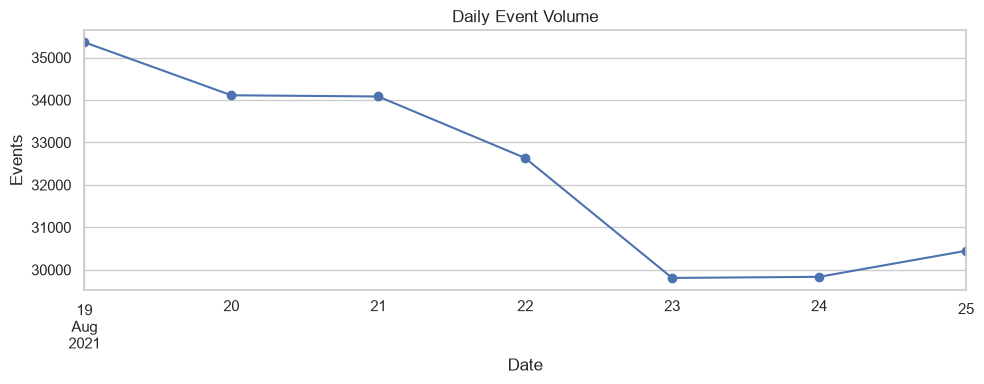

C:\Users\RAC90\AppData\Local\Temp\ipykernel_11800\487196637.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=country_counts.values, y=country_counts.index, palette='Blues_d')


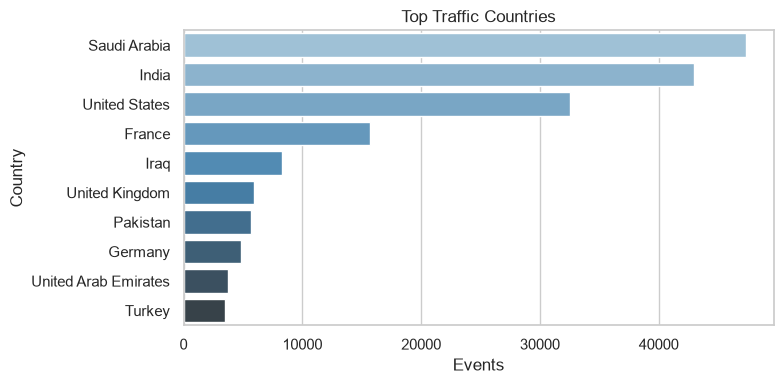

In [5]:
# Visualize daily traffic and country distribution
plt.figure(figsize=(10, 4))
daily_volume = df.set_index('date').resample('D').size()
daily_volume.plot(marker='o')
plt.title('Daily Event Volume')
plt.xlabel('Date')
plt.ylabel('Events')
plt.tight_layout()
plt.show()

country_counts = df['country'].value_counts().head(10)
plt.figure(figsize=(8, 4))
sns.barplot(x=country_counts.values, y=country_counts.index, palette='Blues_d')
plt.title('Top Traffic Countries')
plt.xlabel('Events')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

Top landing pages:
entry_page
c2c876ab-b093-4750-9449-6b4913da6af3    1
a82495d3-5a38-4010-894f-c64fa3b9c6ef    1
9d847c0e-6824-438f-9dc1-d76fca6dc87c    1
2d896d31-97b6-4869-967b-1c5fb9cd4bb8    1
d5317591-872a-487d-87cb-10a516643d5f    1
e849515b-929d-44c8-a505-e7622f1827e9    1
681d888a-59ce-4acb-b7c5-95dab0c063d9    1
Name: count, dtype: int64

Top exit pages:
exit_page
522da5cc-8177-4140-97a7-a84fdb4caf1c    2
e849515b-929d-44c8-a505-e7622f1827e9    2
2d896d31-97b6-4869-967b-1c5fb9cd4bb8    1
cce607e4-1ecb-4ac7-9f83-eb0ce1e1e6d9    1
62d8b57e-0d63-48a0-b856-546e50130534    1
Name: count, dtype: int64


C:\Users\RAC90\AppData\Local\Temp\ipykernel_11800\2749442818.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=entry_pages.values, y=entry_pages.index, palette='viridis')


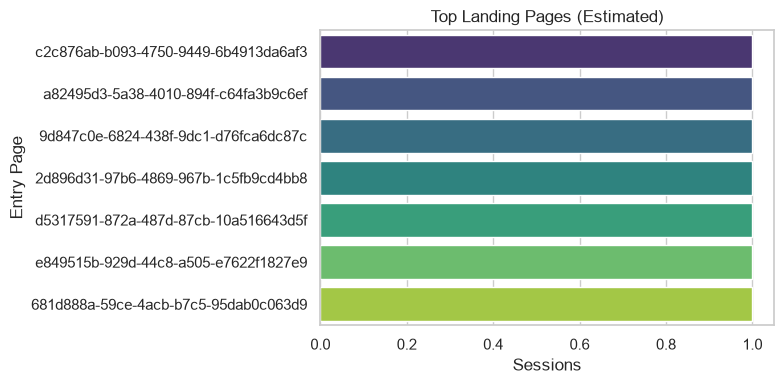

C:\Users\RAC90\AppData\Local\Temp\ipykernel_11800\2749442818.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=exit_pages.values, y=exit_pages.index, palette='magma')


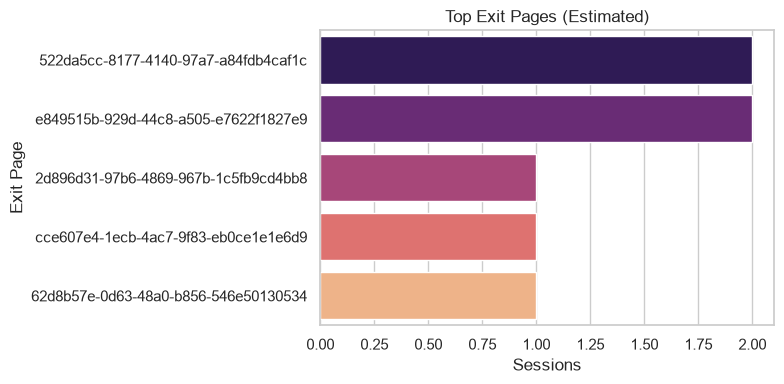

In [6]:
# Analyze landing and exit page behavior
entry_pages = session_metrics['entry_page'].value_counts().head(10)
exit_pages = session_metrics['exit_page'].value_counts().head(10)

print('Top landing pages:')
print(entry_pages)
print('\nTop exit pages:')
print(exit_pages)

plt.figure(figsize=(8, 4))
sns.barplot(x=entry_pages.values, y=entry_pages.index, palette='viridis')
plt.title('Top Landing Pages (Estimated)')
plt.xlabel('Sessions')
plt.ylabel('Entry Page')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(x=exit_pages.values, y=exit_pages.index, palette='magma')
plt.title('Top Exit Pages (Estimated)')
plt.xlabel('Sessions')
plt.ylabel('Exit Page')
plt.tight_layout()
plt.show()

# 📊 Website Traffic Analysis Recommendations

The following recommendations are based on the observed traffic patterns and user behavior analysis.

In [7]:
# Recommendations based on traffic patterns
recommendations = [
    "Improve the highest-traffic landing pages with faster load times, clearer value messaging, and stronger calls to action.",
    "Reduce bounce on one-page sessions by simplifying navigation and promoting the next best step above the fold.",
    "Add recommendation blocks or personalized offers on common exit pages to encourage users to continue browsing.",
    "Tailor landing page experiences for the top traffic-generating countries to improve relevance and conversion rates.",
    "Include page URLs, traffic sources, and unique user identifiers in future data exports to enable complete funnel and conversion analysis."
]

# Display header
print("=" * 80)
print("📊 WEBSITE TRAFFIC ANALYSIS RECOMMENDATIONS".center(80))
print("=" * 80)
print()

# Display recommendations
for i, rec in enumerate(recommendations, start=1):
    print(f"✅ Recommendation {i}")
    print(f"   {rec}\n")

print("=" * 80)
print("End of Recommendations".center(80))
print("=" * 80)

                   📊 WEBSITE TRAFFIC ANALYSIS RECOMMENDATIONS                   

✅ Recommendation 1
   Improve the highest-traffic landing pages with faster load times, clearer value messaging, and stronger calls to action.

✅ Recommendation 2
   Reduce bounce on one-page sessions by simplifying navigation and promoting the next best step above the fold.

✅ Recommendation 3
   Add recommendation blocks or personalized offers on common exit pages to encourage users to continue browsing.

✅ Recommendation 4
   Tailor landing page experiences for the top traffic-generating countries to improve relevance and conversion rates.

✅ Recommendation 5
   Include page URLs, traffic sources, and unique user identifiers in future data exports to enable complete funnel and conversion analysis.

                             End of Recommendations                             
